In [2]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Modelling
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('data/stud_cleaned.csv')
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [29]:
X = df.drop(columns=['math_score', 'average_score', 'total_score'])
X.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


In [30]:
y = df.math_score
y.head()

0    72
1    69
2    90
3    47
4    76
Name: math_score, dtype: int64

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Split columns by type
num_features = X.select_dtypes(exclude='object').columns
cat_features = X.select_dtypes(include='object').columns

#Transformers
numeric_transformer = StandardScaler()
oh_transformer = OneHotEncoder()

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", oh_transformer, cat_features),
        ("StandardScaler", numeric_transformer, num_features),
    ]
)

X = preprocessor.fit_transform(X)

In [32]:
X.shape

(1000, 19)

In [33]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [34]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(),
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor(),
    "SVR": SVR(),
}

In [35]:
model_list = []
r2_list = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    test_rmse = mean_squared_error(y_test, y_test_pred) ** 0.5

    print(name)
    print(f"  Train R2: {train_r2:.4f}")
    print(f"  Test R2:  {test_r2:.4f}")
    print(f"  Test MAE: {test_mae:.4f}")
    print(f"  Test RMSE: {test_rmse:.4f}")
    print("-" * 35)

    model_list.append(name)
    r2_list.append(test_r2)

Linear Regression
  Train R2: 0.8743
  Test R2:  0.8804
  Test MAE: 4.2148
  Test RMSE: 5.3940
-----------------------------------
Lasso
  Train R2: 0.8071
  Test R2:  0.8253
  Test MAE: 5.1579
  Test RMSE: 6.5197
-----------------------------------
Ridge
  Train R2: 0.8743
  Test R2:  0.8806
  Test MAE: 4.2111
  Test RMSE: 5.3904
-----------------------------------
K-Neighbors Regressor
  Train R2: 0.8555
  Test R2:  0.7838
  Test MAE: 5.6210
  Test RMSE: 7.2530
-----------------------------------
Decision Tree
  Train R2: 0.9997
  Test R2:  0.7252
  Test MAE: 6.4950
  Test RMSE: 8.1771
-----------------------------------
Random Forest Regressor
  Train R2: 0.9765
  Test R2:  0.8531
  Test MAE: 4.6429
  Test RMSE: 5.9784
-----------------------------------
XGBRegressor
  Train R2: 0.9955
  Test R2:  0.8278
  Test MAE: 5.0577
  Test RMSE: 6.4733
-----------------------------------
CatBoosting Regressor
  Train R2: 0.9589
  Test R2:  0.8516
  Test MAE: 4.6125
  Test RMSE: 6.0086
-------

In [36]:
results = pd.DataFrame({"Model": model_list, "R2 Score": r2_list})
results.sort_values(by="R2 Score", ascending=False)

,Model,R2 Score
2,Ridge,0.880593
0,Linear Regression,0.880433
8,AdaBoost Regressor,0.853710
5,Random Forest Regressor,0.853121
7,CatBoosting Regressor,0.851632
6,XGBRegressor,0.827797
1,Lasso,0.825320
3,K-Neighbors Regressor,0.783813
9,SVR,0.728600
4,Decision Tree,0.725218


In [40]:
lin_model = LinearRegression()
lin_model.fit(X_train,y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test,y_pred)
print(f"R2 Score : {score*100:.0f}")
print(f"MAE: {mean_absolute_error(y_test,y_pred):.2f}")

R2 Score : 88
MAE: 4.21


Text(0, 0.5, 'Predicted Values')

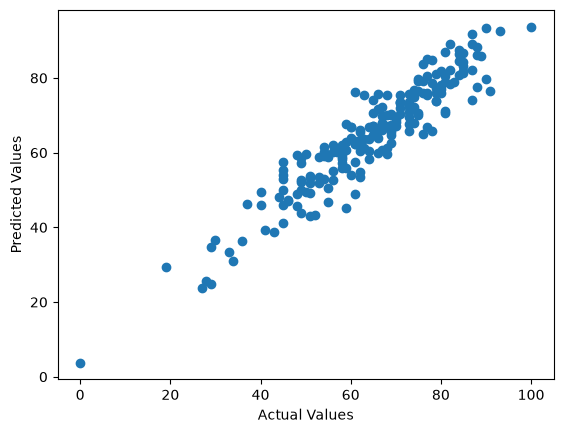

In [38]:
plt.scatter(y_test,y_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

<Axes: xlabel='math_score'>

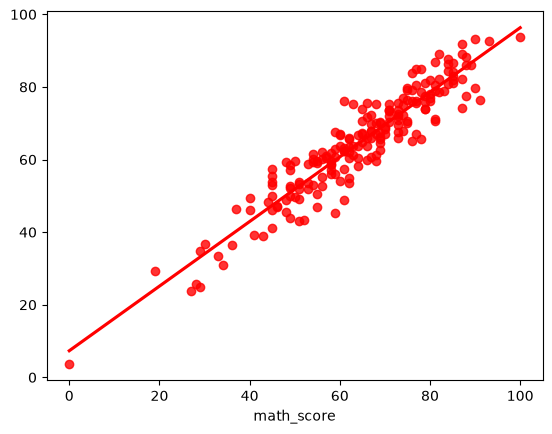

In [39]:
sns.regplot(x=y_test, y=y_pred, ci = None, color='red')